In [1]:
import pandas as pd
import zipfile
import tarfile


## Functions

In [2]:
def read_csv_from_zip(path_fn, filename, **kwargs):
    """
    Opens a zip file at path_fn, reads the specified filename as a CSV, and returns a DataFrame.
    Additional keyword arguments are passed to pd.read_csv.
    """
    with zipfile.ZipFile(path_fn) as z:
        with z.open(filename) as f:
            return pd.read_csv(f, **kwargs)
        
def read_csv_from_tar_gz(path_fn, filename, **kwargs):
    """
    Opens a tar.gz file at path_fn, reads the specified filename as a CSV, and returns a DataFrame.
    Additional keyword arguments are passed to pd.read_csv.
    """
    with tarfile.open(path_fn, "r:gz") as tar:
        member = tar.getmember(filename)
        f = tar.extractfile(member)
        return pd.read_csv(f, **kwargs)

## Constants

In [3]:
FN_APS_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a.zip'
FN_APS_OA_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a_20250120_APSOpenAlex/final_dataset.tar.gz'

FN_CNKI_GIVENNAMES = '../../../results/v3/names/chinese/CNKI_uniqueChineseGivenNames_CNKIpop.csv'
FN_CNKI_GIVENNAMES_SINGLECHAR = '../../../results/v3/names/chinese/CNKI_uniqueChineseCharacter.csv'

FN_CNKI_DEMOGRAPHICS_CLASS = '../../../results/v3/gender/predictions/CNKI_uniqueChineseAllGivenNames_gender_class_median_251_4.csv'
FN_CNKI_DEMOGRAPHICS_REG = '../../../results/v3/gender/predictions/CNKI_uniqueChineseAllGivenNames_gender_reg_mean_224.csv'
FN_CNKI_DEMOGRAPHICS = '../../../results/v3/gender/predictions/CNKI_uniqueChineseAllGivenNames_gender.csv'


## Loading data

In [4]:
_df_aps_authors = read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'authors.csv')
_df_aps_authors_names = read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'author_names.csv')
_df_aps_genders = read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'genders.csv')

df_aps = pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq']] # NOTE: it contains disambiguated True and False

_df_aps_authors.shape, _df_aps_authors_names.shape, _df_aps_genders.shape, df_aps.shape

((874556, 4), (948771, 4), (3, 2), (948771, 5))

In [5]:
df_oa_aps = read_csv_from_tar_gz(FN_APS_OA_DEMOGRAPHICS, 'final_dataset/authors_demographics.csv')
df_oa_aps.shape

(481012, 14)

In [6]:
pinyin_col = 'english'
_df_givennames = pd.read_csv(FN_CNKI_GIVENNAMES, index_col=0)[[pinyin_col]]
_df_givennames_singlechar = pd.read_csv(FN_CNKI_GIVENNAMES_SINGLECHAR).rename(columns={'character':'givenname', 'eng_givenname':pinyin_col}).set_index('givenname')[[pinyin_col]]

# combining existing single_char to multiple char data
df_all_givennames = _df_givennames.join(_df_givennames_singlechar, lsuffix='_m', rsuffix='_s')
df_all_givennames.loc[:, 'english'] = df_all_givennames.apply(lambda row: row.english_m if not pd.notna(row.english_s) else row.english_s, axis=1)
df_all_givennames.drop(columns=['english_m','english_s'], inplace=True)

# adding new single_char to multiple char data
new_names = _df_givennames_singlechar.loc[~_df_givennames_singlechar.index.isin(df_all_givennames.index)]
df_all_givennames = pd.concat([df_all_givennames, new_names], ignore_index=False)
df_all_givennames.rename(columns={pinyin_col:'pinyin'}, inplace=True)
df_all_givennames.loc[:, 'pinyin'] = df_all_givennames.pinyin.apply(lambda v: v.replace("#", " ") if type(v)==str else v)

_df_givennames.shape, _df_givennames_singlechar.shape, df_all_givennames.shape

((39712, 1), (8096, 1), (46144, 1))

In [58]:
_df_givennames.loc['大典']

english    dadian#####daidian#####taidian
Name: 大典, dtype: object

In [20]:
_df_gender_class = pd.read_csv(FN_CNKI_DEMOGRAPHICS_CLASS, index_col=0).set_index('givenname')
_df_gender_reg = pd.read_csv(FN_CNKI_DEMOGRAPHICS_REG, index_col=0).set_index('givenname')
_df_gender = pd.read_csv(FN_CNKI_DEMOGRAPHICS).set_index('givenname')[['gt']]

df_gender_reg = _df_gender_reg.join(df_all_givennames).join(_df_gender)
df_gender_class = _df_gender_class.join(df_all_givennames).join(_df_gender)

df_gender_class.shape, df_gender_reg.shape

((46144, 8), (46144, 7))

### Data

In [8]:
df_aps.head(2)

,id_author,id_author_name,name,gender,gender_nq
0,0,0,S. Megtert,unknown,-
1,1,1,Aleksa Bjeli,male,-


In [9]:
# df_oa_aps.head(2)

In [22]:
df_gender_class.head(2)

,ngender_r,single_char,mean_ngender_rn,mean_ngender_rnw,pred_code,pred_label,pinyin,gt
givenname,,,,,,,,
㑇,NaN,True,NaN,NaN,0,male,zhou,False
㑊,NaN,True,NaN,NaN,0,male,yi,False


In [21]:
df_gender_reg.head(2)

,ngender_r,gender_w,gender_nw,single_char,pred,pinyin,gt
givenname,,,,,,,
㑇,NaN,unknown,male,True,0.313467,zhou,False
㑊,NaN,unknown,male,True,0.313467,yi,False


In [44]:
# This is string matching
# it is difficult to assign a gender to each person.

# Instead, find people from GT in APS, not by name string matching, but by paper matching.
# However, this is impossible as the APS papers are not in the CNKI dataset



def aggregate(v):
    
    counts = v.value_counts(normalize=True)

    if counts.shape[0] == 1:
        return counts.index[0]
   
    if counts.shape[0] == 2:
        if counts.iloc[0] == counts.iloc[1]:
            return 'neutral'
        else:
            return f"mostly_{counts.index[0]}" if counts.index[0] != 'neutral' else 'neutral'

     
    if counts.shape[0] == 3:

        if counts.iloc[0] == counts.iloc[1] == counts.iloc[2]:
            return 'neutral'

        if counts.iloc[0] == 0.5:
            return 'neutral'
        
        if counts.iloc[0] > 0.5:
            return f'mostly_{counts.index[0]}' if counts.index[0] != 'neutral' else 'neutral'
    
        if counts.iloc[0] < 0.5:
            return 'neutral'

    print(counts)
    return None

df_gender_class_pinyin = df_gender_class.reset_index().groupby('pinyin')[['pred_label']].agg(lambda v: aggregate(v))
df_gender_class_pinyin.head(2)
        

,pred_label
pinyin,
a,neutral
a e,neutral


In [52]:
_df_givennames.loc['阿棣']

english    adi#####adai#####ati#####edi#####edai#####eti
Name: 阿棣, dtype: object

<Axes: xlabel='pred_label', ylabel='proportion'>

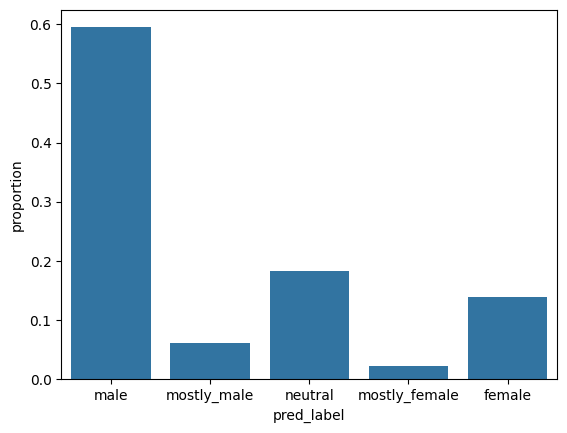

In [ ]:
import seaborn as sns

sns.barplot(data=df_gender_class_pinyin.pred_label.value_counts(normalize=True).to_frame(), x='pred_label', y='proportion', order=['male','mostly_male','neutral','mostly_female','female'])

In [71]:
df_aps.loc[:,'gender_SHJEN'] = None
for pinyin, gender in df_gender_class_pinyin.iterrows():
    pinyin = f" {pinyin} "
    tmp = df_aps.query("name.str.lower().str.contains(@pinyin)")
    if tmp.shape[0] > 0:
        df_aps.loc[tmp.index, 'gender_SHJEN'] = gender
        print(pinyin, gender)
        print(df_aps.loc[tmp.index,['name', 'gender', 'gender_nq', 'gender_SHJEN']])
        print()

 a  pred_label    neutral
Name: a, dtype: object
                            name   gender gender_nq gender_SHJEN
8302                  R. A Meyer     male         -          NaN
23407               M. A Pimenta     male         -          NaN
31378         Robert A Pelcovits     male        gm          NaN
47343             M. A Rodriguez     male         -          NaN
68111               David A Huse     male        gm          NaN
79331              J. A González     male         -          NaN
86864           Howard A Shugart     male        gm          NaN
90713                J. A Torres  unknown         -          NaN
92815               N. A Gippius     male         -          NaN
97737                K. A Penson     male         -          NaN
101624              P. A Crowell     male         -          NaN
102349             I. A Buyanova   female         -          NaN
130313         E. Lizon A Lugrin  unknown         -          NaN
141983             M. A de Vries  unknown

KeyboardInterrupt: 

In [ ]:
df_aps[pd.notna(df_aps.gender_SHJEN)]

,id_author,id_author_name,name,gender,gender_nq,gender_SHJEN


In [69]:
df_gender_class

,ngender_r,single_char,mean_ngender_rn,mean_ngender_rnw,pred_code,pred_label,pinyin,gt
givenname,,,,,,,,
㑇,NaN,True,NaN,NaN,0,male,zhou,False
㑊,NaN,True,NaN,NaN,0,male,yi,False
㕮,NaN,True,NaN,NaN,0,male,fu,False
㘎,NaN,True,NaN,NaN,0,male,han,False
㙍,NaN,True,NaN,NaN,0,male,duo,False
...,...,...,...,...,...,...,...,...
龙香,0.51400,False,0.528420,0.685613,2,female,longxiang,False
龙骧,0.09660,False,0.200083,0.133388,0,male,longxiang,False
龙龙,0.06660,False,0.188975,0.125983,0,male,longlong,False
